---
tags: [tutorial, optimization, variational]
---

# Quantum Optimization with Graph Coloring

In this notebook, we **formulate a graph coloring problem, solve it with QAOA, OpenJij SA, and SCIP, and compare the solutions and execution times.**

We work through five steps using a small graph, introducing terms and equations alongside the code.

| Step | What we do in this notebook | Main code |
| --- | --- | --- |
| 1. Formulate | Define variables, an objective function, and constraints | JijModeling's `problem` |
| 2. Instantiate | Supply the graph and number of colors | `problem.eval()` |
| 3. Conversion | Convert the problem into a QAOA circuit | `QAOAConverter` |
| 4. Solve | Compute expectation values and adjust parameters | `estimate()`, `minimize()` |
| 5. Decode | Recover color assignments from measurement results | `converter.decode()` |

We then compare QAOA with classical solvers and benchmark them as the number of vertices increases.
QAOA expectation values and final measurements are simulated on a classical computer.

In [1]:
# Install Qamomile and the packages used in this notebook.
# !pip install "qamomile[qiskit,visualization]" networkx pandas scipy ommx-openjij-adapter ommx-pyscipopt-adapter

In [2]:
import os
import time

import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from ommx_openjij_adapter import OMMXOpenJijSAAdapter
from ommx_pyscipopt_adapter import OMMXPySCIPOptAdapter
from scipy.optimize import minimize

from qamomile.optimization.qaoa import QAOAConverter
from qamomile.qiskit import QiskitTranspiler

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"
NUM_COLORS = 3
FINAL_SHOTS = 16 if docs_test_mode else 2048  # Shots for obtaining color assignments
MAX_EVALS = 4 if docs_test_mode else 100  # Maximum evaluations for parameter tuning
SA_READS = 2 if docs_test_mode else 500  # Number of simulated annealing reads

## 1. Formulate the Problem

In **graph coloring**, we assign different colors to adjacent vertices: vertices connected by an edge.
Here, we fix the number of available colors at three and minimize the **number of conflicts**, meaning edges whose endpoints have the same color. A value of zero means that the graph has been properly colored with three colors.

We use a four-vertex graph consisting of a triangle with one additional vertex attached.
Vertices 0, 1, and 2 each need a different color. Vertex 3 only needs to differ from vertex 2, so it can use the same color as vertex 0 or 1.

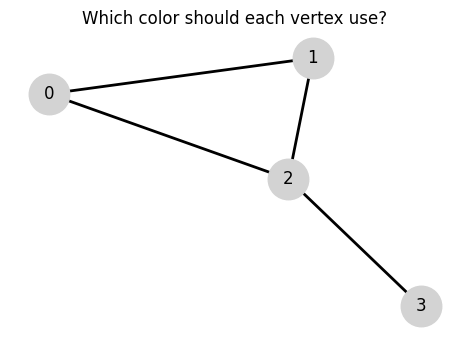

In [3]:
graph = nx.Graph([(0, 1), (1, 2), (0, 2), (2, 3)])
positions = nx.spring_layout(graph, seed=7)

plt.figure(figsize=(4.5, 3))
nx.draw(
    graph, pos=positions, with_labels=True,
    node_color="lightgray", node_size=850, width=2,
)
plt.title("Which color should each vertex use?")
plt.show()

Let $N$ be the number of vertices, $K$ the number of colors, and $E$ the set of edges.
The **decision variable** $x_{v,c}$ is a binary variable: it is 1 when vertex $v$ is assigned color $c$, and 0 otherwise.

The following formulation minimizes the **objective function** $f(x)$, which counts conflicts, subject to the **constraint** that each vertex is assigned exactly one color.

$$
\begin{aligned}
\underset{x\in\{0,1\}^{N\times K}}{\operatorname{minimize}}
\quad & f(x)=\sum_{(u,v)\in E}\sum_{c=0}^{K-1}x_{u,c}x_{v,c}\\
\text{subject to}\quad & \sum_{c=0}^{K-1}x_{v,c}=1
\quad(v=0,\ldots,N-1).
\end{aligned}
$$

This is a **one-hot constraint**: exactly one variable for each vertex must be 1.
For example, $x_{v,1} = 1$ means that vertex $v$ is assigned color 1.
When this constraint holds, the term $\sum_c x_{u,c}x_{v,c}$ for an edge is 1 if its endpoints have the same color, and 0 otherwise.

An assignment that satisfies the constraints is a **feasible solution**. The value of the objective function is the **objective value**.
A feasible solution with the smallest objective value is an **optimal solution**, and that value is the **optimal value**.
In this model, an assignment is feasible as long as each vertex has exactly one color, even if conflicts remain.
A feasible solution with objective value 0 is a proper coloring: every edge has endpoints of different colors.

### Express the Formulation in JijModeling

`N`, `K`, and `E` are placeholders for data that we supply later.
`x` is an array of binary variables with shape `(N, K)`, one for each vertex-color pair.

In the objective, the inner `sum()` sums over colors, and the outer `sum()` sums over edges.
`Constraint(..., domain=N)` adds a one-hot constraint for each vertex.

In [4]:
problem = jm.Problem("Graph Coloring")


@problem.update
def _(problem: jm.DecoratedProblem):
    N = problem.Dim()
    K = problem.Dim()
    E = problem.Natural(ndim=2)
    x = problem.BinaryVar(shape=(N, K))
    # Objective: count edges whose endpoints have the same color
    problem += E.rows().map(
        lambda edge: (x[edge[0], :] * x[edge[1], :]).sum()
    ).sum()
    # Constraint: assign exactly one color to each vertex
    problem += problem.Constraint(
        "one-color", lambda v: x[v, :].sum() == 1, domain=N
    )


problem

Problem(name="Graph Coloring", sense=MINIMIZE, objective=sum(E.rows().map(lambda (edge: Array[:; natural]): sum(x[edge[0], (:)] * x[edge[1], (:)]))), constraints={one-color: [Constraint(name="one-color", , lambda v: sum(x[v, (:)]) == 1, domain=set(N)),],})

## 2. Instantiate the Model

An **instance** is a mathematical model with specific input data supplied.
`problem.eval(instance_data)` substitutes the vertex count, color count, and edges, producing an `Instance` in the common OMMX data format.
The color assignment $x$ has not yet been determined.

Software that solves optimization problems is called a **solver**.
We use this `instance` to solve the same problem with QAOA, OpenJij SA, and SCIP.
Check that the output shows 4 vertices, 3 colors, 12 binary variables, and 4 one-hot constraints.

In [5]:
instance_data = {
    "N": graph.number_of_nodes(),
    "K": NUM_COLORS,
    "E": [list(edge) for edge in graph.edges()],
}
instance = problem.eval(instance_data)
print("vertices:", instance_data["N"])
print("colors:", NUM_COLORS)
print("binary variables:", len(instance.decision_variables))
print("one-hot constraints:", len(instance.constraints))
assert len(instance.decision_variables) == graph.number_of_nodes() * NUM_COLORS
assert len(instance.constraints) == graph.number_of_nodes()

vertices: 4
colors: 3
binary variables: 12
one-hot constraints: 4


## 3. Convert the Problem into a QAOA Circuit

**QUBO** (quadratic unconstrained binary optimization) minimizes a quadratic expression in binary variables without explicit constraints.
`QAOAConverter` adds penalties for constraint violations to the original objective, converts the problem into a QUBO, and then converts it into an Ising model. Our QUBO is

$$
F(x)=f(x)+A\sum_{v=0}^{N-1}\left(\sum_{c=0}^{K-1}x_{v,c}-1\right)^2.
$$

The added term is zero when the one-hot constraints hold and positive when they are violated.
For example, setting every variable to zero gives $f(x)=0$, but incurs a penalty because no colors are assigned.
We set **$A=|E|+1=5$**.
A feasible solution has $F(x)=f(x)\leq |E|$; a candidate that violates a constraint has $F(x)\geq A$.
The optimal solution of the QUBO therefore also satisfies the constraints.

Substituting $x=(1-z)/2$ replaces binary variables with spin variables $z\in\{+1,-1\}$, giving an Ising model.
Using the corresponding cost Hamiltonian, `transpile(..., p=1)` creates a single-layer QAOA circuit.
This model needs no auxiliary variables, so the qubit count equals the number of binary variables: $NK=12$.

`normalize_by_abs_max()` normalizes the coefficients by dividing them all by the same positive constant. This leaves the bit strings with minimum energy unchanged.
Calling `executor()` without arguments sets up execution using the default simulator.

In [6]:
penalty_weight = graph.number_of_edges() + 1
converter = QAOAConverter(instance, uniform_penalty_weight=penalty_weight)
converter.spin_model.normalize_by_abs_max(replace=True)

transpiler = QiskitTranspiler()
qaoa = converter.transpile(transpiler, p=1)
executor = transpiler.executor()

print("penalty weight:", penalty_weight)
print("QAOA qubits:", converter.spin_model.num_bits)
assert converter.spin_model.num_bits == len(instance.decision_variables)

penalty weight: 5
QAOA qubits: 12


## 4. Adjust the Circuit Parameters

We adjust the QAOA circuit parameters to lower the expected energy, including penalties.
With one layer, there are two parameters to adjust: $\gamma,\beta$.

`remove_final_measurements()` creates a circuit without measurements for expectation evaluation.
`energy()` uses `params[0]` as $\gamma$ and `params[1]` as $\beta$, then calls `executor.estimate()` to compute the expectation value.
It calculates this directly from the statevector, so no shots are needed here.

We adjust the parameters with `minimize()`, then obtain color assignments from the final measurements in the next section.

In [7]:
state_circuit = qaoa.quantum_circuit.remove_final_measurements(inplace=False)
hamiltonian = converter.get_cost_hamiltonian()


def energy(params):
    circuit = state_circuit.assign_parameters({
        "gammas[0]": params[0], "betas[0]": params[1],
    })
    return executor.estimate(circuit, hamiltonian)


initial_params = np.random.default_rng(7).uniform(0.0, np.pi, 2)
optimized = minimize(
    energy, initial_params, method="COBYLA",
    options={"maxiter": MAX_EVALS},
)
print("optimized parameters:", optimized.x)

optimized parameters: [3.82315881 2.00087508]


## 5. Decode Measurements into Color Assignments

Using the optimized parameters, we take `FINAL_SHOTS` measurement shots and call `converter.decode()` to map each candidate back to the variables of the original OMMX instance.
We then evaluate whether it satisfies the one-hot constraints and compute the original objective value $f(x)$.
Measurement results vary from run to run.

The expected energy minimized in the previous section includes penalties.
**To compare solutions, we use the original objective value without penalties.** For a feasible solution, this is the number of conflicts.

`best_feasible_or_none()` selects the feasible solution with the smallest objective value among those obtained.
QAOA does not guarantee that any of its samples satisfy the constraints, so the function returns `None` if no feasible solution is found.

In [8]:
def best_feasible_or_none(samples):
    if not samples.summary["feasible"].any():
        return None
    return samples.best_feasible


final_sample = qaoa.sample(
    executor,
    shots=FINAL_SHOTS,
    bindings={
        "gammas": [optimized.x[0]],
        "betas": [optimized.x[1]],
    },
).result()
qaoa_samples = converter.decode(final_sample)
qaoa_solution = best_feasible_or_none(qaoa_samples)

if qaoa_solution is None:
    print("No one-hot-feasible sample. Try more shots or another seed.")
else:
    print("best conflicts:", qaoa_solution.objective)
    print("proper coloring:", np.isclose(qaoa_solution.objective, 0))

best conflicts: 0.0
proper coloring: True


### Inspect the Color Assignment

`extract_decision_variables("x")` retrieves each `(vertex index, color index)` pair and its variable value.
Because the selected solution satisfies the one-hot constraints, the variables with value 1 identify each vertex's color.

In the figure, `v: c` means "vertex index: color index." Conflicting edges are drawn in red, and their count appears as `conflict(s)` in the title.

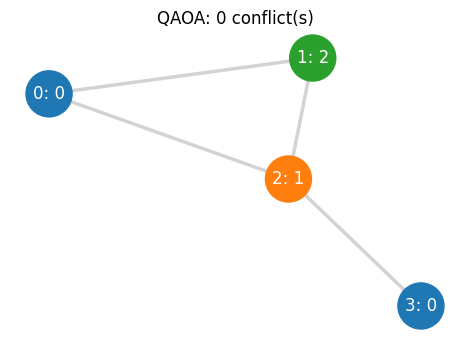

vertex -> color: {0: 0, 1: 2, 2: 1, 3: 0}


In [9]:
if qaoa_solution is not None:
    values = qaoa_solution.extract_decision_variables("x")
    assignment = {v: c for (v, c), value in values.items() if value > 0.5}
    conflicts = [
        (u, v) for u, v in graph.edges if assignment[u] == assignment[v]
    ]
    assert np.isclose(qaoa_solution.objective, len(conflicts))
    palette = plt.get_cmap("tab10")
    plt.figure(figsize=(4.5, 3))
    nx.draw(
        graph, pos=positions,
        labels={v: f"{v}: {assignment[v]}" for v in graph.nodes},
        node_color=[palette(assignment[v]) for v in graph.nodes],
        edge_color=["tab:red" if e in conflicts else "lightgray" for e in graph.edges],
        width=2.5, node_size=1100, font_color="white",
    )
    plt.title(f"QAOA: {len(conflicts)} conflict(s)")
    plt.show()
    print("vertex -> color:", assignment)

## 6. Compare with Classical Solvers

We pass the same `instance` to OMMX Adapters, which convert it into the format each solver requires.
The following two solvers solve the same problem as QAOA.

- **OpenJij SA** runs simulated annealing. We use the same penalty weight as QAOA and set the number of reads to `SA_READS`.
- **SCIP** handles the original objective and constraints. We use its optimal value as the reference.

For QAOA and SA, we select the feasible solution with the smallest objective value among those obtained.
We compare that value with SCIP's optimal value to check whether the selected solution is optimal.

In [10]:
openjij_samples = OMMXOpenJijSAAdapter.sample(
    instance,
    num_reads=SA_READS,
    uniform_penalty_weight=penalty_weight,
)
openjij_solution = best_feasible_or_none(openjij_samples)

scip_solution = OMMXPySCIPOptAdapter.solve(instance)
assert scip_solution.feasible and np.isclose(scip_solution.objective, 0)

We compare the results using the objective value of the original problem.

| Column | Meaning |
| --- | --- |
| `best` | The smallest objective value among the feasible solutions obtained |
| `gap` | `best` minus SCIP's optimal value |
| `feasible_rate` | Fraction of returned candidates that are feasible (0–1) |

**`best=0` means there are no conflicts; `gap=0` means the solution is optimal.**
For example, if a problem has optimal value 1 and we obtain a feasible solution with objective value 1, then `best=1` and `gap=0`.
If no feasible solution is found, `best` and `gap` are `NaN` (missing data). SCIP returns a feasible solution, so we set its `feasible_rate` to 1.0 here.

In [11]:
solutions = {"QAOA": qaoa_solution, "OpenJij SA": openjij_solution, "SCIP": scip_solution}
comparison = pd.DataFrame([
    {"method": method, "best": np.nan if solution is None else solution.objective}
    for method, solution in solutions.items()
])
comparison["gap"] = comparison["best"] - scip_solution.objective
comparison["feasible_rate"] = [
    qaoa_samples.summary["feasible"].mean(),
    openjij_samples.summary["feasible"].mean(),
    1.0,
]
comparison

,method,best,gap,feasible_rate
0,QAOA,0.0,0.0,0.137207
1,OpenJij SA,0.0,0.0,1.000000
2,SCIP,0.0,0.0,1.000000


## 7. Benchmark Across Problem Sizes

Finally, we vary the number of vertices across 3, 4, 5, and 6, comparing **the gap to the optimal value and execution time**.
We keep the color count fixed at `NUM_COLORS`. With three colors, these problems use 9, 12, 15, and 18 qubits, respectively.

For each size, we generate a random graph by connecting each pair of vertices with probability 0.5, then add the edges `(0, 1), (1, 2), ...` to make the graph connected.
We fix the random seed for graph generation and pass the same OMMX instance to all three methods.
A proper coloring may not exist with the available colors, so we use SCIP to determine the optimal value for each size.

QAOA and SA both use the penalty weight $A=|E|+1$.
QAOA uses one layer. Its final measurement shot count and evaluation budget, and the SA read count, use the shared constants defined at the start.

In [12]:
problem_sizes = [3] if docs_test_mode else [3, 4, 5, 6]

We collect the QAOA steps from Sections 3–5 into `solve_with_qaoa()`.
It returns the selected solution (or `None` if none is feasible) and the fraction of feasible samples.

The following loop records the time before and after each solver's processing to calculate elapsed time.

In [13]:
def solve_with_qaoa(instance, penalty_weight, seed):
    converter = QAOAConverter(instance, uniform_penalty_weight=penalty_weight)
    converter.spin_model.normalize_by_abs_max(replace=True)
    transpiler = QiskitTranspiler()
    qaoa = converter.transpile(transpiler, p=1)
    executor = transpiler.executor()

    state_circuit = qaoa.quantum_circuit.remove_final_measurements(inplace=False)
    hamiltonian = converter.get_cost_hamiltonian()

    def energy(params):
        circuit = state_circuit.assign_parameters({
            "gammas[0]": params[0], "betas[0]": params[1],
        })
        return executor.estimate(circuit, hamiltonian)

    initial = np.random.default_rng(seed).uniform(0.0, np.pi, 2)
    optimized = minimize(
        energy, initial, method="COBYLA",
        options={"maxiter": MAX_EVALS},
    )
    sample = qaoa.sample(
        executor,
        shots=FINAL_SHOTS,
        bindings={
            "gammas": [optimized.x[0]],
            "betas": [optimized.x[1]],
        },
    ).result()
    samples = converter.decode(sample)
    return best_feasible_or_none(samples), samples.summary["feasible"].mean()

In [14]:
benchmark_rows = []
for num_vertices in problem_sizes:
    benchmark_graph = nx.gnp_random_graph(
        num_vertices, p=0.5, seed=1000 + num_vertices
    )
    benchmark_graph.add_edges_from((v, v + 1) for v in range(num_vertices - 1))
    benchmark_instance = problem.eval({
        "N": num_vertices,
        "K": NUM_COLORS,
        "E": [list(edge) for edge in benchmark_graph.edges()],
    })
    penalty = benchmark_graph.number_of_edges() + 1
    qubits = num_vertices * NUM_COLORS
    print(f"Solving N={num_vertices}, edges={benchmark_graph.number_of_edges()}, qubits={qubits}")

    started = time.perf_counter()
    scip_best = OMMXPySCIPOptAdapter.solve(benchmark_instance)
    scip_elapsed = time.perf_counter() - started
    reference = scip_best.objective

    started = time.perf_counter()
    sa_samples = OMMXOpenJijSAAdapter.sample(
        benchmark_instance,
        num_reads=SA_READS,
        uniform_penalty_weight=penalty,
    )
    sa_best = best_feasible_or_none(sa_samples)
    sa_rate = sa_samples.summary["feasible"].mean()
    sa_elapsed = time.perf_counter() - started

    started = time.perf_counter()
    qaoa_best, qaoa_rate = solve_with_qaoa(
        benchmark_instance, penalty, seed=7 + num_vertices
    )
    qaoa_elapsed = time.perf_counter() - started
    for method, solution, elapsed, feasible_rate in [
        ("QAOA", qaoa_best, qaoa_elapsed, qaoa_rate),
        ("OpenJij SA", sa_best, sa_elapsed, sa_rate),
        ("SCIP", scip_best, scip_elapsed, 1.0),
    ]:
        best = np.nan if solution is None else solution.objective
        benchmark_rows.append({
            "vertices": num_vertices,
            "qubits": qubits,
            "edges": benchmark_graph.number_of_edges(),
            "method": method,
            "best": best,
            "gap": best - reference,
            "feasible_rate": feasible_rate,
            "seconds": elapsed,
        })

Solving N=3, edges=3, qubits=9


Solving N=4, edges=3, qubits=12


Solving N=5, edges=6, qubits=15


Solving N=6, edges=12, qubits=18


`best`, `gap`, and `feasible_rate` are the same metrics as in Section 6. The following columns also show problem size and execution time.

| Column | Meaning |
| --- | --- |
| `vertices` | Number of vertices |
| `qubits` | Number of QAOA qubits |
| `edges` | Number of edges |
| `seconds` | Elapsed time in seconds, from problem conversion through solving, solution evaluation, and selection |

Timing excludes OMMX instance creation and plotting.
If no feasible solution is found, `best` and `gap` are `NaN`, and the next plot omits the `gap` point for that size.

In [15]:
benchmark = pd.DataFrame(benchmark_rows)
assert len(benchmark) == 3 * len(problem_sizes)
assert (benchmark["gap"].dropna() >= -1e-8).all()
benchmark

,vertices,qubits,edges,method,best,gap,feasible_rate,seconds
0,3,9,3,QAOA,0.0,0.0,0.272949,0.566427
1,3,9,3,OpenJij SA,0.0,0.0,1.000000,0.043070
2,3,9,3,SCIP,0.0,0.0,1.000000,0.001924
3,4,12,3,QAOA,0.0,0.0,0.178711,0.598149
4,4,12,3,OpenJij SA,0.0,0.0,1.000000,0.051118
5,4,12,3,SCIP,0.0,0.0,1.000000,0.002008
6,5,15,6,QAOA,0.0,0.0,0.191406,0.843493
7,5,15,6,OpenJij SA,0.0,0.0,1.000000,0.048426
8,5,15,6,SCIP,0.0,0.0,1.000000,0.002609
9,6,18,12,QAOA,1.0,0.0,0.010254,2.821321


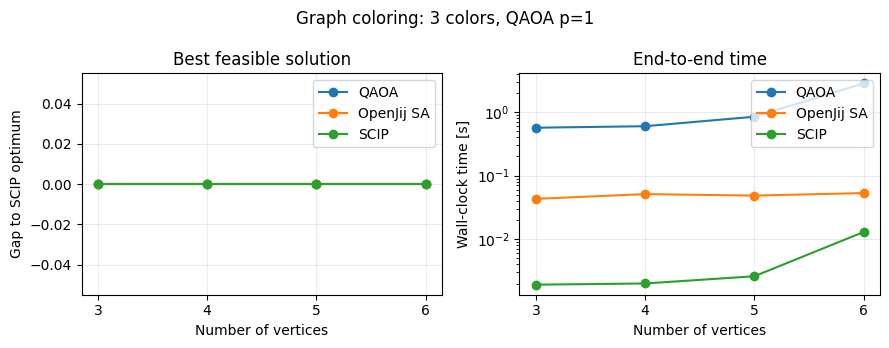

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for method, rows in benchmark.groupby("method", sort=False):
    axes[0].plot(rows["vertices"], rows["gap"], "o-", label=method)
    axes[1].plot(rows["vertices"], rows["seconds"], "o-", label=method)

axes[0].set(title="Best feasible solution", ylabel="Gap to SCIP optimum")
axes[1].set(title="End-to-end time", ylabel="Wall-clock time [s]", yscale="log")
for axis in axes:
    axis.set_xlabel("Number of vertices")
    axis.set_xticks(problem_sizes)
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(f"Graph coloring: {NUM_COLORS} colors, QAOA p=1")
plt.tight_layout()
plt.show()

The left plot compares the gap to the optimal value; the right plot compares execution time on a logarithmic vertical scale.
For sizes where all methods reach the optimum, the lines on the left overlap at zero.

:::{note}
Each timing covers one graph and one run at the given size. We optimize the QAOA angles ($\gamma,\beta$) and keep the layer count, evaluation budget, and SA settings fixed. Comparing solver performance more broadly would require multiple graphs, random seeds, and settings. The QAOA timings here measure classical simulation.
:::

## Summary

We formulated the problem in JijModeling, created a QAOA circuit from an OMMX instance, and evaluated the resulting solutions against the original problem.
Passing the same instance to classical solvers let us **compare the objective values of feasible solutions and execution times on a common basis**.

For API details, see the [JijModeling modeling guide](https://jij-inc-jijmodeling-tutorials-en.readthedocs-hosted.com/en/v2.6.0/basics/modeling.html) and
the [Qamomile QAOAConverter reference](../api/optimization/qaoa.md).

Adapted from the [QCE 2026 tutorial](https://github.com/Jij-Inc/Qamomile-QCE2026-Tutorial/blob/main/docs/tutorials/en/05_quantum_optimization_graph_coloring.ipynb).